In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path(r"C:\ML_Agin\fraud-detection-final\data\raw\creditcard.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Dataset shape: (284807, 31)
Number of rows: 284807
Number of columns: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
print("Column names:")
print(df.columns.tolist())

print("\nClass distribution:")
display(df["Class"].value_counts().sort_index())

print("\nClass percentages:")
display(
    (df["Class"].value_counts(normalize=True).sort_index() * 100).round(4)
)

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Class distribution:


Class
0    284315
1       492
Name: count, dtype: int64


Class percentages:


Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


Missing values: 0
Duplicate rows: 1081


In [3]:
print("Transaction counts:")
print(df["Class"].value_counts().sort_index())

print("\nTransaction percentages:")
print(
    (df["Class"].value_counts(normalize=True).sort_index() * 100).round(4)
)

Transaction counts:
Class
0    284315
1       492
Name: count, dtype: int64

Transaction percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nStatistical summary:")
display(df[["Time", "Amount"]].describe().T)

Missing values: 0
Duplicate rows: 1081

Data types:
float64    30
int64       1
Name: count, dtype: int64

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16


In [5]:
duplicate_rows = df[df.duplicated(keep=False)]

print("Rows involved in duplicate groups:", len(duplicate_rows))

print("\nClass distribution among duplicate rows:")
print(duplicate_rows["Class"].value_counts().sort_index())

print("\nClass distribution in the full dataset:")
print(df["Class"].value_counts().sort_index())

Rows involved in duplicate groups: 1854

Class distribution among duplicate rows:
Class
0    1822
1      32
Name: count, dtype: int64

Class distribution in the full dataset:
Class
0    284315
1       492
Name: count, dtype: int64


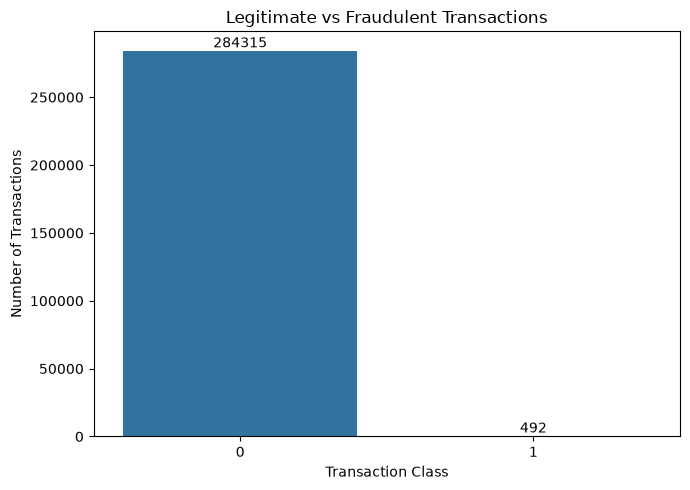

In [6]:
class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=class_counts.index.astype(str),
    y=class_counts.values
)

ax.set_title("Legitimate vs Fraudulent Transactions")
ax.set_xlabel("Transaction Class")
ax.set_ylabel("Number of Transactions")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()

In [7]:
fraud_count = (df["Class"] == 1).sum()
legitimate_count = (df["Class"] == 0).sum()
fraud_percentage = (fraud_count / len(df)) * 100

print(f"Total transactions: {len(df):,}")
print(f"Legitimate transactions: {legitimate_count:,}")
print(f"Fraudulent transactions: {fraud_count:,}")
print(f"Fraud percentage: {fraud_percentage:.4f}%")

Total transactions: 284,807
Legitimate transactions: 284,315
Fraudulent transactions: 492
Fraud percentage: 0.1727%
